# DATA VISUALIZATION ASSIGNMENT

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('pokemon_data.csv')
df

,dexnum,name,generation,type1,type2,species,height,weight,ability1,ability2,...,catch_rate,base_friendship,base_exp,growth_rate,egg_group1,egg_group2,percent_male,percent_female,egg_cycles,special_group
0,1,Bulbasaur,1,Grass,Poison,Seed Pokémon,0.7,6.9,Overgrow,Chlorophyll,...,45,50,64,Medium Slow,Grass,Monster,87.5,12.5,20,Ordinary
1,2,Ivysaur,1,Grass,Poison,Seed Pokémon,1.0,13.0,Overgrow,Chlorophyll,...,45,50,142,Medium Slow,Grass,Monster,87.5,12.5,20,Ordinary
2,3,Venusaur,1,Grass,Poison,Seed Pokémon,2.0,100.0,Overgrow,Chlorophyll,...,45,50,236,Medium Slow,Grass,Monster,87.5,12.5,20,Ordinary
3,4,Charmander,1,Fire,NaN,Lizard Pokémon,0.6,8.5,Blaze,Solar Power,...,45,50,62,Medium Slow,Dragon,Monster,87.5,12.5,20,Ordinary
4,5,Charmeleon,1,Fire,NaN,Flame Pokémon,1.1,19.0,Blaze,Solar Power,...,45,50,142,Medium Slow,Dragon,Monster,87.5,12.5,20,Ordinary
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,1021,Raging Bolt,9,Electric,Dragon,Paradox Pokémon,5.2,480.0,Protosynthesis,NaN,...,10,—,—,Slow,Undiscovered,NaN,NaN,NaN,—,Ancient Paradox
1021,1022,Iron Boulder,9,Rock,Psychic,Paradox Pokémon,1.5,162.5,Quark Drive,NaN,...,10,—,—,Slow,Undiscovered,NaN,NaN,NaN,—,Future Paradox
1022,1023,Iron Crown,9,Steel,Psychic,Paradox Pokémon,1.6,156.0,Quark Drive,NaN,...,10,—,—,Slow,Undiscovered,NaN,NaN,NaN,—,Future Paradox
1023,1024,Terapagos,9,Normal,NaN,Tera Pokémon,0.2,6.5,Tera Shift,NaN,...,255,—,—,Slow,Undiscovered,NaN,50.0,50.0,—,Legendary


# 1. Distribution of HP
- Plot a histogram of the hp column using Seaborn or Matplotlib.
- Add a reasonable number of bins (e.g., 10–20)
- Task: What range of HP values seems most common?


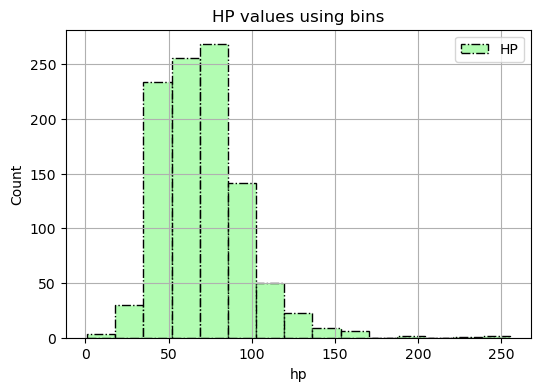

In [128]:
fig = plt.figure(figsize=(6,4))
sns.histplot(data = df , x = 'hp', bins = 15,
            color = 'palegreen',linestyle = '-.',edgecolor = 'black', label = 'HP')

plt.title('HP values using bins')
plt.grid(True)
plt.legend()

the range where the most Pokémon live in 50 - 90

# 2. Distribution of Speed
- Plot a histogram of the speed column.
- Task: Are there more slow Pokémon or fast Pokémon? (Look at where most bars are concentrated.)


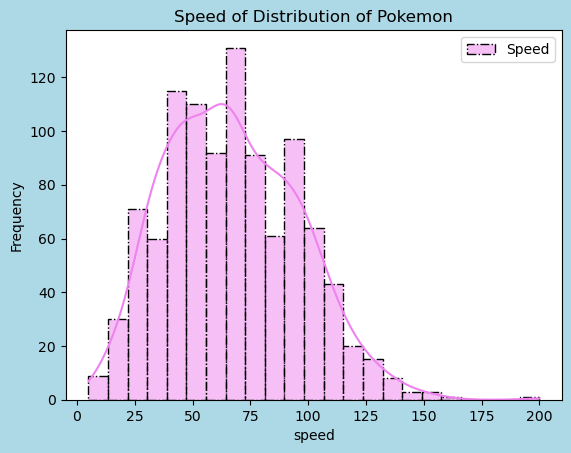

In [5]:
fig = plt.figure(facecolor = 'lightblue')
sns.histplot(data = df, x = df['speed'],color = 'violet',
             linestyle = '-.',label = 'Speed',kde = True)

plt.title('Speed of Distribution of Pokemon')
plt.ylabel('Frequency')
plt.legend()

# 3. Count of Pokémon by Primary Type (type1)
- Create a countplot of type1 to see how many Pokémon exist of each primary type.
- Task: Which primary type has the most Pokémon? Which types are relatively rare?

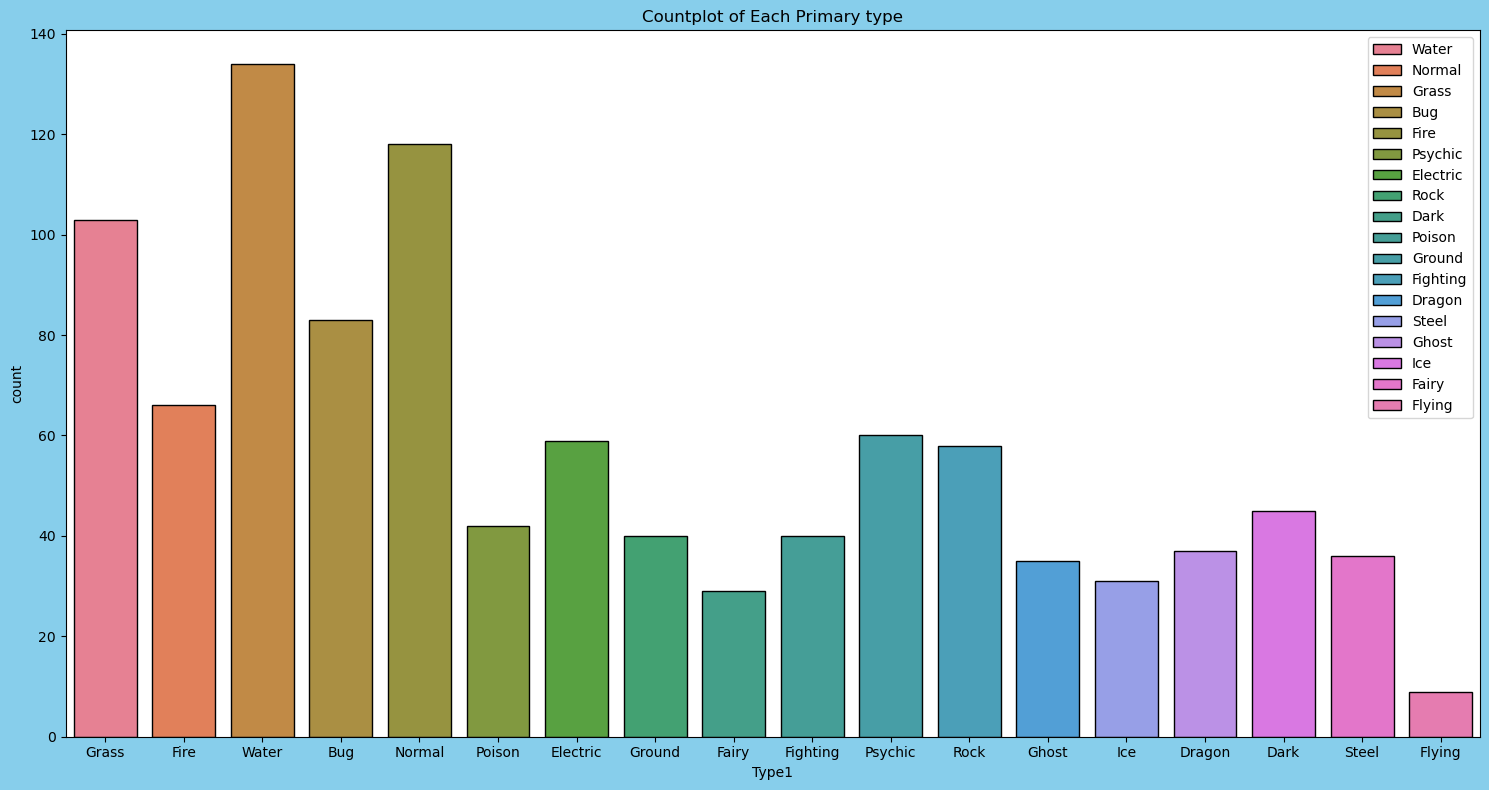

In [133]:
fig = plt.figure(facecolor = 'skyblue',figsize = (15,8))
sns.countplot(data = df, x = df['type1'], hue = 'type1',
             edgecolor = 'black')
plt.title('Countplot of Each Primary type')
plt.xlabel('Type1')
plt.legend(labels = df['type1'].value_counts().index)
plt.tight_layout()

# Answer
- Water primary type has the most Pokeman
- Flying primary types are realtively raare

# 4. Average Attack by Primary Type
- Group the data by type1 and calculate the mean attack for each type.
- Plot this as a bar plot (type on x-axis, average attack on y-axis).
- Task: Which type1 has the highest average attack?


In [3]:
avg = df.groupby('type1')['attack'].agg(['mean'])

In [5]:
avg_values = avg.sort_values(by = 'mean').reset_index()
avg_values

,type1,mean
0,Psychic,63.000000
1,Fairy,66.827586
2,Bug,67.554217
3,Ghost,68.600000
4,Water,72.343284
5,Electric,72.966102
6,Grass,74.349515
7,Normal,74.381356
8,Ice,74.419355
9,Poison,75.547619


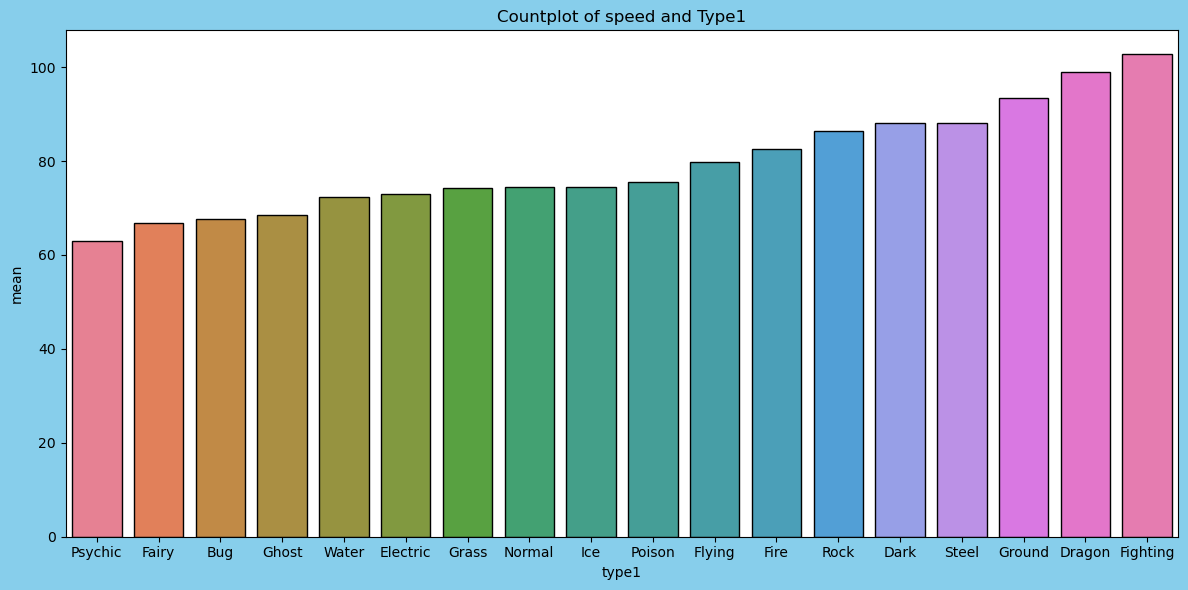

In [6]:
fig = plt.figure(facecolor = 'skyblue',figsize=(12,6))
sns.barplot(data = avg_values, x = 'type1', y = 'mean' ,hue = 'type1',
             edgecolor = 'black')
plt.title('Countplot of speed and Type1')
plt.tight_layout()

# Answer 
- Fighting has the highest average attack

# 5. Speed by Primary Type (Boxplot)
- Draw a boxplot with:
  - x-axis: type1
  - y-axis: speed
- Task: Which type1 tends to have the fastest Pokémon (higher median)? Which types show a large spread in Speed? (Hint: You may rotate x-axis labels for readability.)


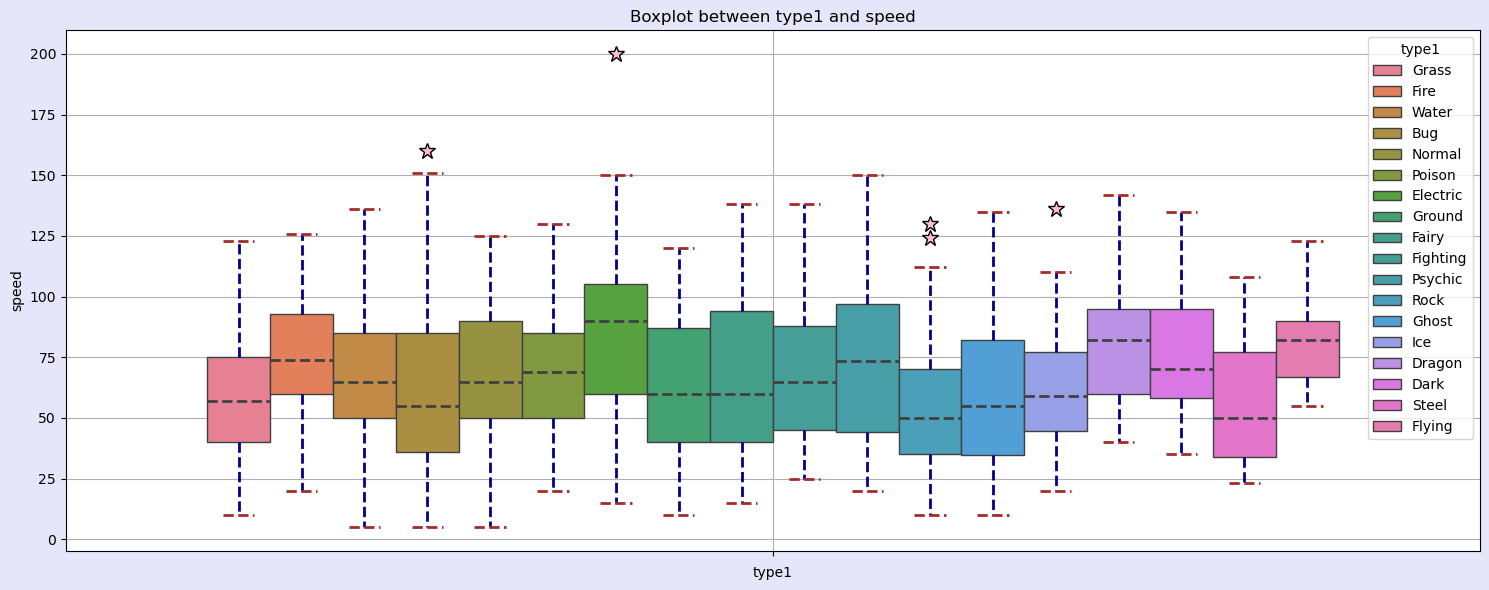

In [148]:
fig = plt.figure(figsize= (15,6),facecolor = 'lavender')
sns.boxplot(data = df, y = 'speed',hue = 'type1',
           medianprops = dict(linestyle = '--',linewidth = 2),
           whiskerprops = dict(linestyle = '--',linewidth = 2, color = 'darkblue'),
           capprops = dict(linestyle = '--', linewidth = 2,color = 'brown'),
           flierprops = dict(marker = '*',markersize = 12,markeredgecolor = 'black',markerfacecolor = 'pink'))
plt.title('Boxplot between type1 and speed')
plt.xlabel('type1')
plt.grid(True)
plt.tight_layout()

# 6. Comparison Across Generations: Count of Pokémon
- Use a countplot (or bar plot) to show the number of Pokémon in each generation.
- Task: Which Generation has the most Pokémon in this dataset?


Text(0.5, 1.0, 'Count plot of Generation')

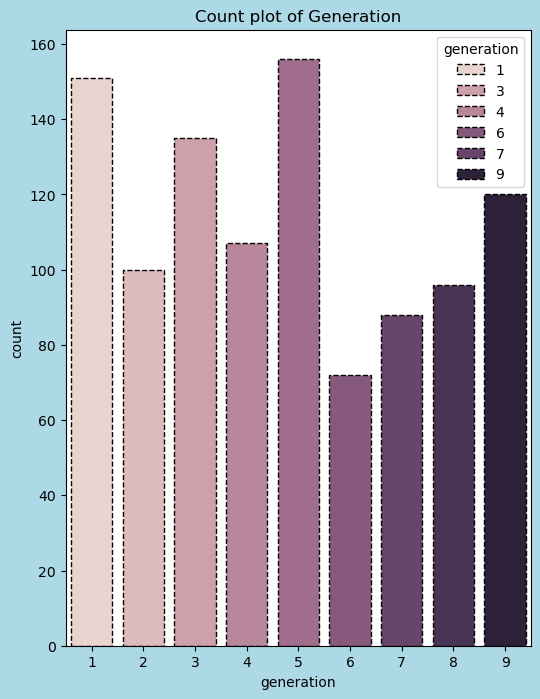

In [99]:
fig = plt.figure(facecolor = 'lightblue', figsize = (6,8))
sns.countplot(data = df, x = df['generation'], hue = 'generation',
             edgecolor = 'black',linestyle = '--')
plt.title('Count plot of Generation')

# Answer: 
- 5th generation has the most Pokemon in this dataset

# 7. Average Total Stats by Generation
- Group by generation and compute the average of total.
- Plot a bar plot of generation vs average total.
- Task: Do later generations seem to have higher or lower total stats on average?


In [86]:
avg_generation = df.groupby('generation')['total'].agg(['mean']).reset_index()
avg_generation

,generation,mean
0,1,407.642384
1,2,407.180000
2,3,403.725926
3,4,445.570093
4,5,425.756410
5,6,429.305556
6,7,449.409091
7,8,439.218750
8,9,457.391667


Text(0.5, 1.0, 'Total mean of each generation')

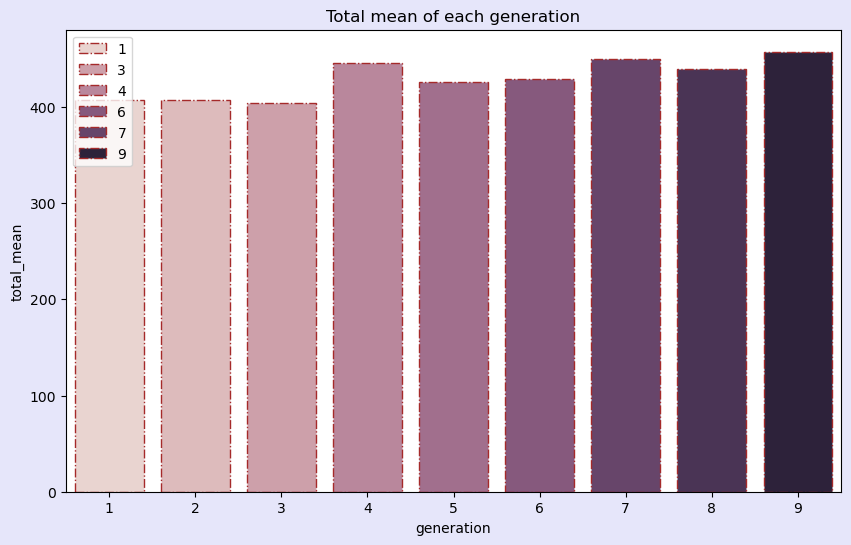

In [105]:
fid = plt.figure(figsize = (10,6),facecolor = 'lavender')
sns.barplot(data = avg_generation, x = 'generation', y = 'mean', 
            hue = 'generation',linestyle = '-.',edgecolor = 'brown')
plt.legend(loc = 'upper left')
plt.ylabel('total_mean')
plt.title('Total mean of each generation')

# Q) Task: Do later generations seem to have higher or lower total stats on average?
- Answer: later generation have higher total stats on average


# 8. Relationship Between Attack and Defense
- Make a scatter plot:
- x-axis: attack
- y-axis: defense.
- Task: Is there any visible relationship between attack and defense (e.g., do high-attack Pokémon also tend to have high defense)?


In [106]:
df[['attack', 'defense']].corr()

,attack,defense
attack,1.000000,0.465565
defense,0.465565,1.000000


Text(0.5, 1.0, 'Scatterplot in between attack and Defense')

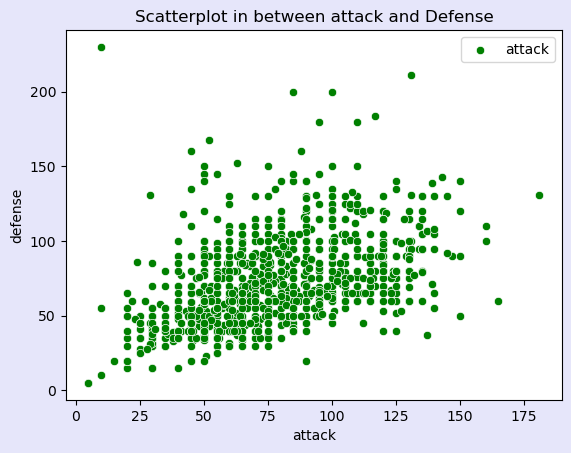

In [152]:
plt.figure(facecolor = 'lavender')
sns.scatterplot(data = df, x = 'attack', y = 'defense', label = 'attack',color = 'green')
plt.title('Scatterplot in between attack and Defense')


# Answer
- From the scatterplot, there is no strong linear relationship between Attack and Defense.

# 9. Relationship Between Speed and Total
- Create a scatter plot of:
- x-axis: speed
- y-axis: total.
- Task: Do faster Pokémon generally have higher total stats, or is it spread out?


In [111]:
df[['speed', 'total']].corr()

,speed,total
speed,1.000000,0.553797
total,0.553797,1.000000


Text(0.5, 1.0, 'Scatterplot in between speed and total')

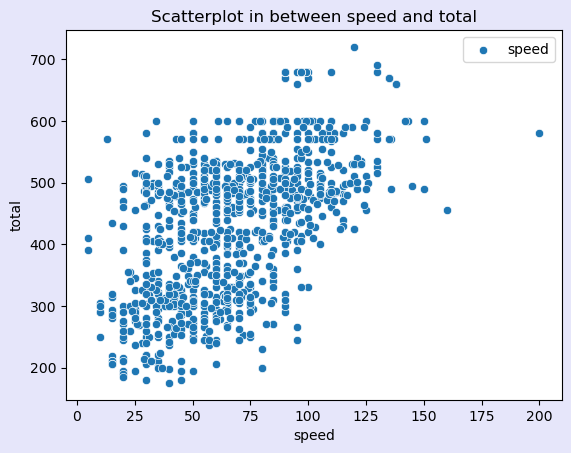

In [153]:
plt.figure(facecolor = 'lavender')
sns.scatterplot(data = df, x = 'speed', y = 'total', label = 'speed')
plt.title('Scatterplot in between speed and total')


# Answer
- Faster Pokémon tend to have slightly higher total stats, but the relationship is not strong.
- There is a wide spread of total stats at almost every speed level, meaning speed alone does not determine how strong a Pokémon is overall.

# 10. Heatmap of Correlations Between Stats
- Select only numeric stat columns: ['hp', 'attack', 'defense', 'sp_atk', 'sp_def', 'speed', 'total'].
- Compute their correlation matrix using df[cols].corr().
- Plot a heatmap of this correlation matrix using sns.heatmap (with annot=True if possible).
- Task: Which pair of stats seems most strongly positively correlated? Is any stat weakly related to the others?


In [115]:
df[['hp', 'attack', 'defense', 'sp_atk', 'sp_def', 'speed', 'total']]

,hp,attack,defense,sp_atk,sp_def,speed,total
0,45,49,49,65,65,45,318
1,60,62,63,80,80,60,405
2,80,82,83,100,100,80,525
3,39,52,43,60,50,65,309
4,58,64,58,80,65,80,405
...,...,...,...,...,...,...,...
1020,125,73,91,137,89,75,590
1021,90,120,80,68,108,124,590
1022,90,72,100,122,108,98,590
1023,90,65,85,65,85,60,450


In [117]:
df[['hp', 'attack', 'defense', 'sp_atk', 'sp_def', 'speed', 'total']].corr()

,hp,attack,defense,sp_atk,sp_def,speed,total
hp,1.000000,0.476141,0.299013,0.359616,0.369087,0.179877,0.667127
attack,0.476141,1.000000,0.465565,0.281880,0.226126,0.351055,0.714396
defense,0.299013,0.465565,1.000000,0.210107,0.503281,0.008047,0.629466
sp_atk,0.359616,0.281880,0.210107,1.000000,0.493034,0.423150,0.701154
sp_def,0.369087,0.226126,0.503281,0.493034,1.000000,0.214105,0.697998
speed,0.179877,0.351055,0.008047,0.423150,0.214105,1.000000,0.553797
total,0.667127,0.714396,0.629466,0.701154,0.697998,0.553797,1.000000


Text(0.5, 1.0, 'Heatmap plot among numerical columns')

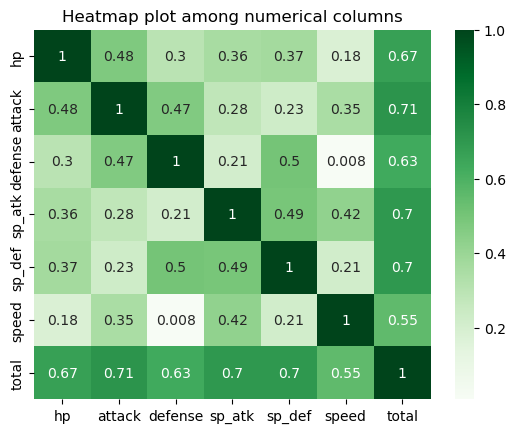

In [122]:
sns.heatmap(df[['hp', 'attack', 'defense', 'sp_atk', 'sp_def', 'speed', 'total']].corr(),
            annot = True,cmap = 'Greens')
plt.title('Heatmap plot among numerical columns')

# Answer
- The highest correation among the dataset is total & attack -> 0.712
- and waekest correaltion in the table is speed & defense -> 0.0080